In [1]:
import sys, os; sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath('')), 'Utilities'))
import batman
import numpy as np
import matplotlib.pyplot as plt
import batman_utils
import kepler_utils as k

In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period [days]
rp = 0.02                                   #planet radius [stellar radii]
rs = 0.68                                   # stellar radius [solar radii]
a_AU = 0.007                                #semi-major axis [AU]
a = k.AU_to_RS(a_AU, rs)         #semi-major axis [stellar radii] 
incl = 86.3                                 #orbital inclination [degrees]
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron [degrees] 
fp = 142.9e-6                               #planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm

u = [0.1, 0.3]                              # Stellar limb darkening coefficients [u1, u2] (placeholders, not from K2-141 data, will be set by theoretical stellar atmosphere models)

offset = 0.                                 # hotspot offset delta (atmospheric winds redistributing heat east of substellar point, in degrees)

t = np.linspace(-period/4, period*3/4, 10000)

### Transit

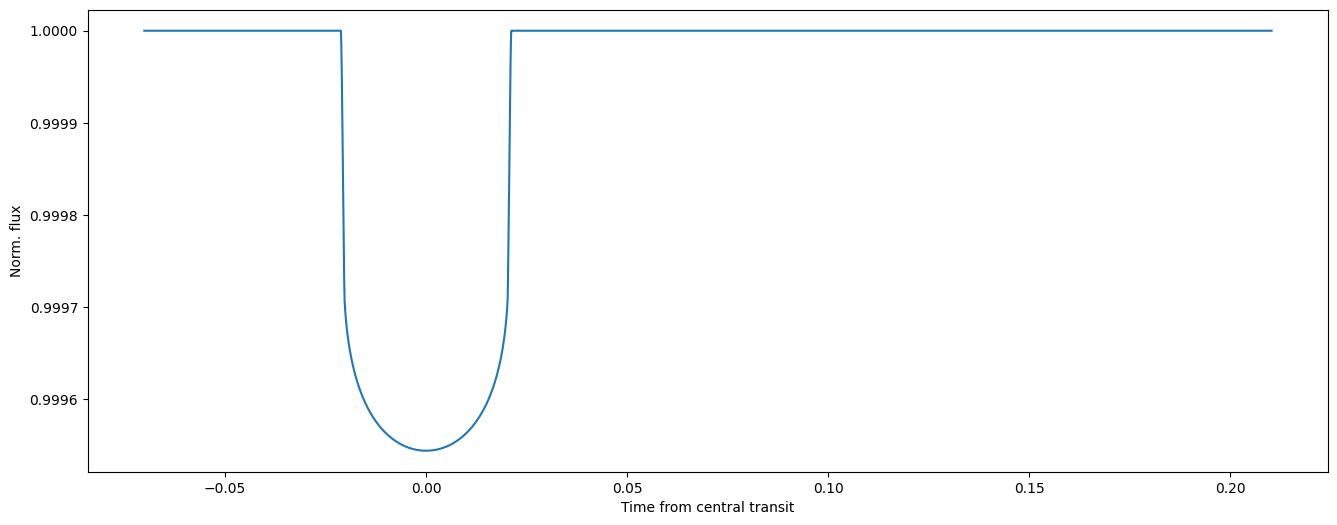

In [3]:
plt.figure(figsize=(16, 6))
plt.plot(t, batman_utils.flux_transit(period, rp, a, incl, ecc, w, t, u=u))
plt.xlabel("Time from central transit")
plt.ylabel("Norm. flux")
plt.show()

### Occultation

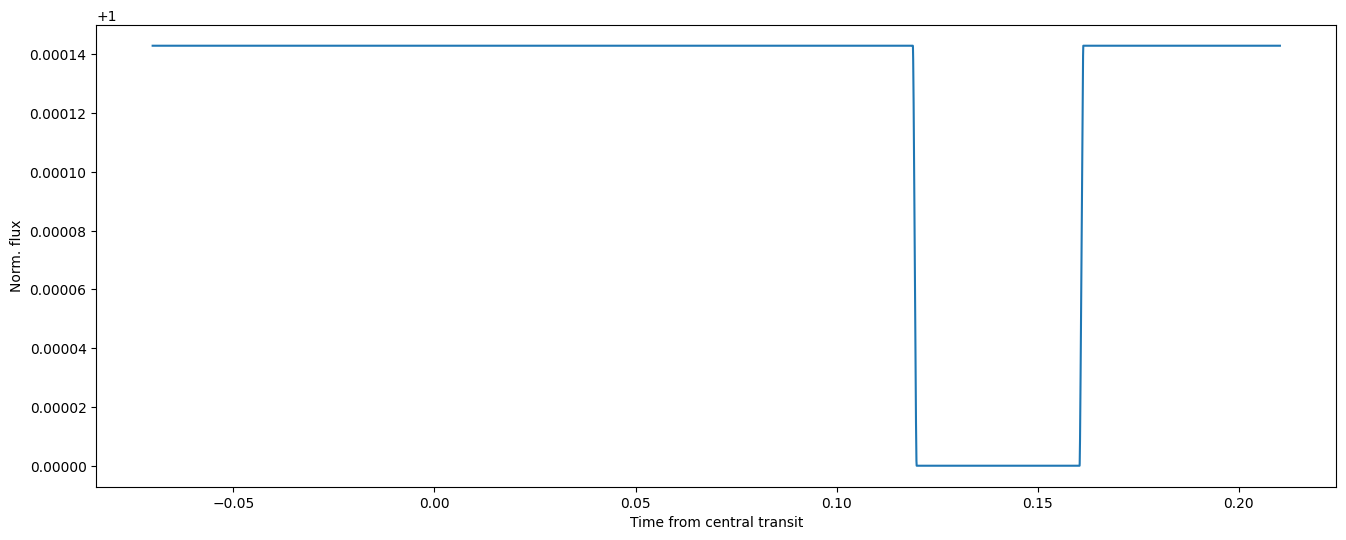

In [4]:
plt.figure(figsize=(16, 6))
plt.plot(t, batman_utils.flux_occultation(period, rp, a, incl, ecc, w, fp, t, u=u))
plt.xlabel("Time from central transit")
plt.ylabel("Norm. flux")
plt.show()

### Occultation + Planetary Phases

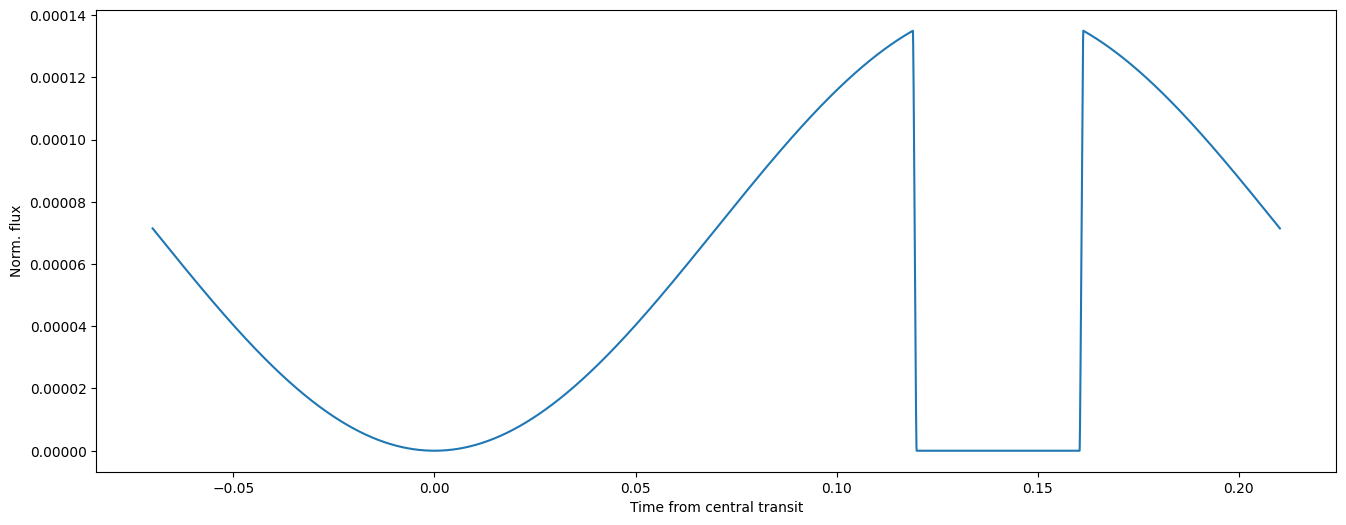

In [5]:
Amp=1. # Phase Curve Amplitude ( A = 1 - F_p,min / F_p,max = (T_night / T_day)^4 )
phase_mod = 1 + Amp/2 * (np.cos(2*np.pi * (t/period - 0.5) + np.radians(offset)) - 1)
plt.figure(figsize=(16, 6))
plt.plot(t, (batman_utils.flux_occultation(period, rp, a, incl, ecc, w, fp, t, u=u)-1)*phase_mod)
plt.xlabel("Time from central transit")
plt.ylabel("Norm. flux")
plt.show()

### Transit + Occultation + Planetary Phases

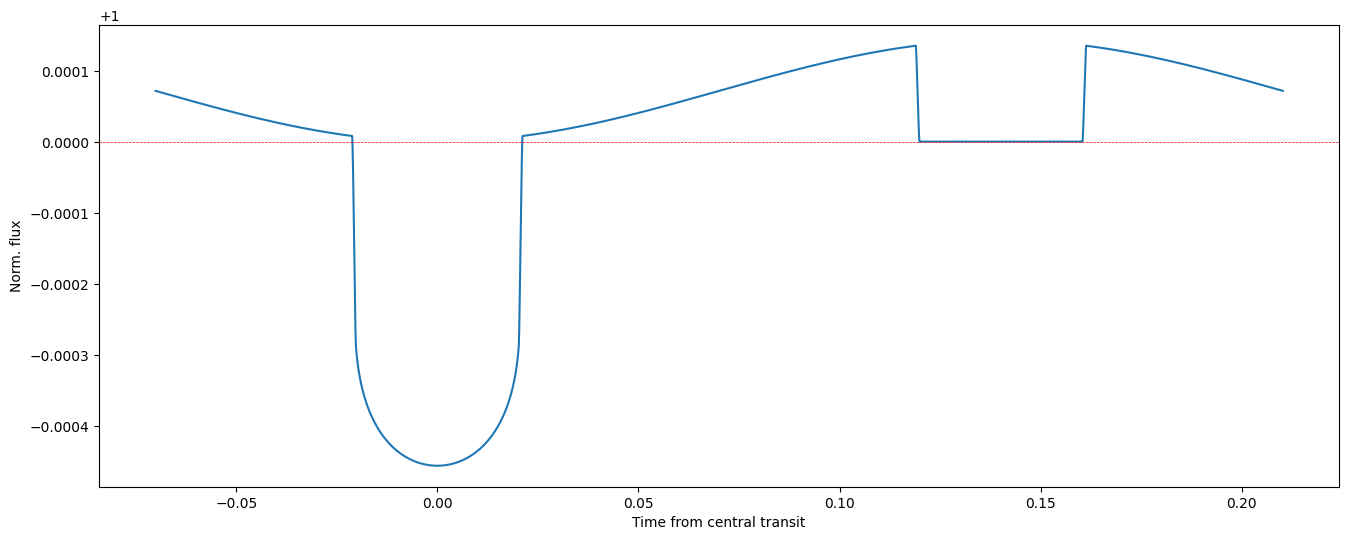

In [6]:
plt.figure(figsize=(16, 6))
plt.plot(t, batman_utils.flux_transit(period, rp, a, incl, ecc, w, t, u=u)+(batman_utils.flux_occultation(period, rp, a, incl, ecc, w, fp, t, u=u)-1)*phase_mod)
plt.axhline(1, color='r', linestyle='--', linewidth=0.5)
plt.xlabel("Time from central transit")
plt.ylabel("Norm. flux")
plt.show()

## Complete observable PhaseCurve

In [9]:
t, flux = batman_utils.PhaseCurve(period, rp, a, incl, ecc, w, fp, rs, u=u)

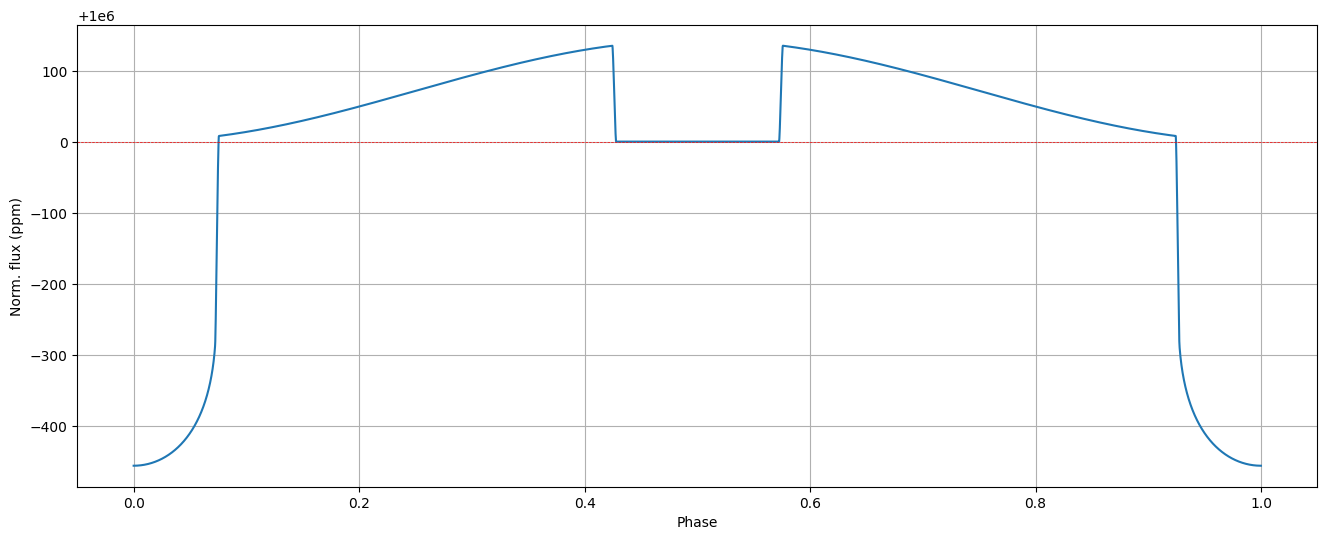

In [10]:
plt.figure(figsize=(16, 6))
plt.plot(t/period, flux*1e6)
plt.axhline(1e6, color='r', linestyle='--', linewidth=0.5)
plt.xlabel("Phase")
plt.ylabel("Norm. flux (ppm)")
# plt.minorticks_on()
# plt.grid(which='minor')
plt.grid(which='major')
plt.show()